# HSE RecSys Challenge 2026 — финальное решение

Быстрый воспроизводимый pipeline: EDA → 80/20 validation → Popularity → ItemKNN → EASE → нумерованные submissions. SASRec уже обучен отдельно; обычный Run All не требует GPU, PyTorch или RePlay.


In [1]:
from pathlib import Path
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "pyproject.toml").is_file() and (PROJECT_ROOT.parent / "pyproject.toml").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "pyproject.toml").is_file():
    raise FileNotFoundError("Запустите notebook из корня репозитория или папки notebooks/")
%pip install -q -e '{PROJECT_ROOT}[dev]'
import shutil

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from recsys.classical import fit_ease, fit_itemknn, popularity_scores, score
from recsys.data import (chronological_user_split, eda_summary, ground_truth,
                         interaction_matrix, load_data, make_mappings, resolve_data_dir)
from recsys.metrics import recall_at_k
from recsys.submission import (build_submission, recommendations_from_scores,
                               validate_submission, write_submission)

SEED, K = 42, 10
EASE_GRID = [100.0, 300.0, 1000.0, 3000.0, 10000.0]
OUTPUT_DIR = PROJECT_ROOT / "submissions"
OUTPUT_DIR.mkdir(exist_ok=True)
np.random.seed(SEED)


/Users/dmitrijkanevskij/VS_CodeProjects/data_science/recsystems/hse_recsys_competition/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


## Данные и EDA

Ratings не порогуются: каждое событие является бинарным взаимодействием.


,table,rows,columns,missing,duplicates
0,events,894149,4,0,0
1,user_features,6040,3,0,0
2,item_features,3706,19,0,0
3,sample,6040,2,0,0


,events
rating,
1,50256
2,96001
3,233824
4,312170
5,201898


,history_length
count,6040.000000
mean,148.037914
std,173.461681
min,14.000000
25%,38.000000
50%,84.500000
75%,186.000000
max,2056.000000


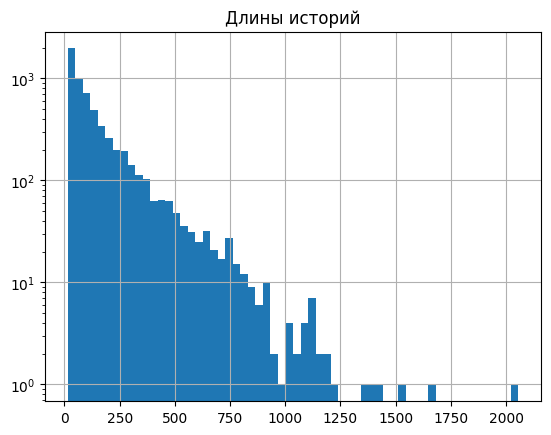

In [2]:
DATA_DIR = resolve_data_dir(PROJECT_ROOT / "data")
tables = load_data(DATA_DIR)
events, user_features, item_features, sample = (
    tables[name] for name in ["events", "user_features", "item_features", "sample"])
mappings = make_mappings(user_features, item_features)
display(eda_summary(tables))
display(events.rating.value_counts().sort_index().rename("events").to_frame())
display(events.groupby("user_id").size().describe().rename("history_length").to_frame())
events.groupby("user_id").size().hist(bins=60)
plt.yscale("log"); plt.title("Длины историй"); plt.show()


### Выводы по данным

Датасет содержит **894 149 взаимодействий**, **6 040 пользователей** и каталог из **3 706 фильмов**. Пропусков и полных дубликатов в исходных таблицах не обнаружено.

Распределение пользовательской активности неоднородно: медианная история содержит **84,5 взаимодействия**, тогда как наиболее активный пользователь имеет **2 056**. Это означает, что модели должны учитывать пользователей с очень разным объёмом истории.

Оценки 4 и 5 составляют большинство взаимодействий. В текущих экспериментах мы не используем величину `rating` как вес: любое взаимодействие трактуется как бинарный сигнал. Это упрощает сравнение моделей, но не позволяет различать положительные и отрицательные предпочтения.

## Chronological validation 80/20

У каждого пользователя скрываются последние `ceil(20%)` событий. Все validation targets недоступны моделям и train-only статистикам.


In [3]:
train, valid = chronological_user_split(events, 0.20)
train_matrix = interaction_matrix(train, mappings)
train_seen = interaction_matrix(train, mappings)
targets = ground_truth(valid)
validation_users = list(targets)
validation_rows = np.array([mappings.user_to_index[user] for user in validation_users])
assert set(train.index).isdisjoint(valid.index)
assert (train.groupby("user_id").timestamp.max() < valid.groupby("user_id").timestamp.min()).all()
train_popularity = popularity_scores(train_matrix)

def evaluate(score_matrix):
    recommendations = recommendations_from_scores(
        score_matrix, validation_users, mappings.item_ids, train_seen,
        mappings.user_to_index, K, train_popularity)
    return recall_at_k(recommendations, targets, K)

results = []
print({"train": len(train), "validation": len(valid), "users": len(targets)})


{'train': 712916, 'validation': 181233, 'users': 6040}


### Выводы по валидации

Мы получили **712 916 interactions для обучения** и **181 233 для валидации**, сохранив всех 6 040 пользователей.

Вместо единой глобальной временной точки используется chronological 80/20 split внутри каждой пользовательской истории. Это связано с тем, что `timestamp` отражает относительный порядок событий, а не общую календарную шкалу.

Такой подход сохраняет порядок взаимодействий и предотвращает использование будущих событий конкретного пользователя при обучении. Все признаки и веса моделей вычисляются по train, а validation используется только для проверки качества.

Это наша локальная оценка; способ построения скрытого теста Kaggle неизвестен.

## Popularity и ItemKNN

Popularity служит sanity baseline. ItemKNN использует binary cosine similarity, shrinkage 10 и top-100 соседей. После local evaluation ItemKNN переобучается на всех observed events для submission №1.


In [4]:
pop_scores = np.broadcast_to(
    train_popularity, (len(validation_users), len(mappings.item_ids)))
pop_recall = evaluate(pop_scores)
results.append({"model": "Popularity", "local_recall_at_10": pop_recall})

knn_weights = fit_itemknn(train_matrix, neighbors=100, shrinkage=10.0)
knn_recall = evaluate(score(train_matrix[validation_rows], knn_weights))
results.append({"model": "ItemKNN", "local_recall_at_10": knn_recall})

full_matrix = interaction_matrix(events, mappings)
full_popularity = popularity_scores(full_matrix)
sample_users = sample.user_id.tolist()
sample_rows = np.array([mappings.user_to_index[user] for user in sample_users])
full_knn_weights = fit_itemknn(full_matrix, neighbors=100, shrinkage=10.0)
full_knn_scores = score(full_matrix[sample_rows], full_knn_weights)
itemknn_recommendations = recommendations_from_scores(
    full_knn_scores, sample_users, mappings.item_ids, full_matrix,
    mappings.user_to_index, K, full_popularity)
itemknn_submission = build_submission(sample, itemknn_recommendations, K)
validate_submission(itemknn_submission, sample, events, mappings.item_ids, K)
write_submission(OUTPUT_DIR / "1_submission_itemknn.csv", itemknn_submission)
display(pd.DataFrame(results))


,model,local_recall_at_10
0,Popularity,0.036167
1,ItemKNN,0.058408


### Выводы: Popularity → ItemKNN

| Модель | Local Recall@10 |
|---|---:|
| Popularity | 0.036167 |
| ItemKNN | **0.058408** |

ItemKNN заметно превосходит неперсонализированный baseline: использование совместных взаимодействий позволяет учитывать историю конкретного пользователя.

Таким образом, **collaborative filtering действительно извлекает полезный сигнал из данных**, даже без нейросетевых моделей и сложного feature engineering.

После локальной оценки ItemKNN переобучен на всех доступных взаимодействиях и сформирован первый Kaggle submission.

**Следующая гипотеза:** вместо фиксированного выбора ближайших соседей можно совместно обучить веса между всеми фильмами с помощью EASE.

## EASE и submission №2

Пять λ сравниваются на том же 80/20 holdout. После выбора лучшего λ выполняется один full-data refit и экспорт unseen top-10.


In [9]:
ease_rows = []
for regularization in EASE_GRID:
    weights = fit_ease(train_matrix, regularization)
    value = evaluate(score(train_matrix[validation_rows], weights))
    ease_rows.append({"lambda": regularization, "local_recall_at_10": value})
ease_results = pd.DataFrame(ease_rows).sort_values("local_recall_at_10", ascending=False)
best_ease_lambda = float(ease_results.iloc[0]["lambda"])
results.append({"model": f"EASE λ={best_ease_lambda:g}",
                "local_recall_at_10": float(ease_results.iloc[0]["local_recall_at_10"])})

full_ease_weights = fit_ease(full_matrix, best_ease_lambda)
full_ease_scores = score(full_matrix[sample_rows], full_ease_weights)
ease_recommendations = recommendations_from_scores(
    full_ease_scores, sample_users, mappings.item_ids, full_matrix,
    mappings.user_to_index, K, full_popularity)
ease_submission = build_submission(sample, ease_recommendations, K)
validate_submission(ease_submission, sample, events, mappings.item_ids, K)
write_submission(OUTPUT_DIR / "2_submission_ease.csv", ease_submission)
display(ease_results)
display(pd.DataFrame(results).sort_values("local_recall_at_10", ascending=False))


,lambda,local_recall_at_10
2,1000.0,0.065038
3,3000.0,0.064884
1,300.0,0.063336
4,10000.0,0.062299
0,100.0,0.061258


,model,local_recall_at_10
2,EASE λ=1000,0.065038
3,EASE λ=1000,0.065038
1,ItemKNN,0.058408
0,Popularity,0.036167


### Выводы: EASE и подбор регуляризации

Мы проверили пять значений коэффициента регуляризации `λ`. Лучший результат показал **EASE с λ = 1000**, получив **Recall@10 = 0.065038**.

По сравнению с ItemKNN (`0.058408`) качество выросло примерно на **11,4% относительно исходного значения**.

EASE обучает item-item коэффициенты совместно, а не ограничивается локальными cosine similarities. Это позволило улучшить качество без увеличения сложности модели до нейросетевой архитектуры.

EASE стал нашим **лучшим классическим подходом**. При этом ни EASE, ни ItemKNN не используют порядок взаимодействий — это мотивирует следующий эксперимент с SASRec.

После выбора регуляризации мы обучили EASE на всех известных взаимодействиях и создали второй submission.

## SASRec: подтверждённый финальный результат

SASRec обучен только в [`sasrec_colab_standalone.ipynb`](sasrec_colab_standalone.ipynb). Текущий сохранённый запуск выбрал **epoch 49** и получил **local Recall@10 = 0.141219** на 80/20. Для неизменённого `sasrec_outputs/submission_sasrec.csv` пользователь подтвердил **Kaggle Recall@10 = 0.2842** (30.10.2026). Исторический ориентир другой сессии — 0.141546 на epoch 48; это не метрика текущего checkpoint.

Следующая ячейка только копирует уже отправленный CSV в нумерованную коллекцию; обучение и inference не запускаются.


In [10]:
sasrec_source = PROJECT_ROOT / "sasrec_outputs/submission_sasrec.csv"
sasrec_numbered = OUTPUT_DIR / "3_submission_sasrec.csv"
if not sasrec_source.is_file():
    raise FileNotFoundError("Не найден сохранённый Kaggle submission: " + str(sasrec_source))
shutil.copyfile(sasrec_source, sasrec_numbered)
assert sasrec_source.read_bytes() == sasrec_numbered.read_bytes()
sasrec_submission = pd.read_csv(sasrec_numbered, dtype=str)
validate_submission(sasrec_submission, sample, events, mappings.item_ids, K)
print("№4 побайтно совпадает с Kaggle submission; Recall@10 = 0.2842")


№4 побайтно совпадает с Kaggle submission; Recall@10 = 0.2842


## Итоговые результаты и выводы

| Модель | Kaggle Recall@10 |
|---|---:|
| ItemKNN | 0.0647 |
| EASE | 0.0860 |
| **SASRec** | **0.2842** |

Самый большой прирост качества дал переход от классических collaborative filtering моделей к **последовательной рекомендательной модели SASRec**.

SASRec учитывает порядок предыдущих взаимодействий пользователя с помощью causal self-attention. Для обучения использовались sliding windows и autoregressive next-item prediction.

Лучшая модель на локальной валидации достигла **Recall@10 = 0.141219 на эпохе 49**. После выбора эпохи мы отдельно обучили модель на всех доступных взаимодействиях и получили финальный Kaggle submission.

Полный цикл обучения вынесен в автономную Colab-тетрадку `sasrec_colab_standalone.ipynb`. Веса, конфигурация и отображения идентификаторов сохранены, поэтому модель можно восстановить для inference без повторного обучения.

**Главный вывод:** для нашего датасета моделирование последовательности взаимодействий оказалось значительно эффективнее статических item-item методов. При этом простые модели остались полезными воспроизводимыми baseline, относительно которых можно оценить реальный вклад SASRec.